In [1]:
import flwr as fl
import torch
import os

In [2]:
BATCH_SIZE=32
LEARNING_RATE = 0.01
NUM_EPOCHS = 1000
INPUT_SIZE = 5
OUTPUT_SIZE = 2
HIDDEN_SIZE = 128
NUM_LAYERS = 4

target_feature_names = ['throughput', 'delay']
RESULTS_DIR = "../results/"

FUTURE_WIN_LEN = 5
WINDOW_LEN = 15
STRIDE = FUTURE_WIN_LEN
FILTER_LEN = 5

NUM_CLIENTS=7
NUM_ROUNDS=500
FRACTION_FIT=0.7
MIN_FIT_CLIENTS=3

In [3]:
import math
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm

from sklearn.metrics import r2_score


import torch
import torch.nn as nn 
from torch.utils.data import Dataset, DataLoader, random_split
import torch.optim as optim
from torch.optim import lr_scheduler

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)

cuda


In [4]:
import pandas as pd

df = pd.read_csv('./../ML-Aided-NR-V2X-QoS-Predictions/dataset.csv')
df.drop(columns='Unnamed: 0', inplace=True)
# df.head()

In [5]:
df.drop_duplicates(inplace = True)
# df.dropna(inplace=True)

In [6]:
cols = ['throughput', 'sinr', 'dlpathloss', 'delay', 'jitter']

delay_index = cols.index('delay')
tp_index = cols.index('throughput')

In [7]:
from sklearn.linear_model import LinearRegression
clean = df[['distance', 'pdr']].dropna()

model = LinearRegression()
model.fit(clean[['pdr']], clean[['distance']])
missing_dist = df['distance'].isnull()
predicted = model.predict(df.loc[missing_dist, ['pdr']])
df.loc[missing_dist, 'distance'] = predicted

In [8]:
clean = df[['jitter', 'delay']].dropna()
model = LinearRegression()
model.fit(clean[['delay']], clean[['jitter']])
missing_jitter = df['jitter'].isnull()
predicted = model.predict(df.loc[missing_jitter, ['delay']])
df.loc[missing_jitter, 'jitter'] = predicted

In [9]:
cols_to_smoothen = ['sinr', 'dlpathloss', 'jitter']
for col in cols_to_smoothen:
    df[col] = df[col].rolling(window=FILTER_LEN).mean()

df.bfill(inplace=True)
df.ffill(inplace=True)

# df.head(15)

In [10]:
def sliding_window_augmentation(df, cols, indices, future_window_len=1, L=100, s=10, add_noise=True, noise_level=0.02):
    X = df[cols].values
    T, D = X.shape

    n_windows = max(0, (T - L - future_window_len) // s + 1)

    if n_windows <= 0:
        return np.array([]), np.array([])

    num_targets = len(indices)
    windows = np.zeros((n_windows, L, D))
    targets = np.zeros((n_windows, future_window_len, num_targets))

    col_stds = df[cols].std().values

    for i in range(n_windows):
        start = i * s
        end_input = start + L
        end_target = end_input + future_window_len

        w = X[start:end_input].copy()
        
        target = X[end_input:end_target, indices].copy()

        if add_noise:
            input_noise = np.random.randn(*w.shape) * col_stds * noise_level 
            w += input_noise

            target_noise = np.random.randn(future_window_len, num_targets) * col_stds[indices] * noise_level
            target += target_noise

        windows[i] = w
        targets[i] = target

    return windows, targets

In [11]:
from torch.utils.data import Dataset, DataLoader

class QosDataset(Dataset):
    def __init__(self, windowed_data, target):
        self.X = torch.tensor(windowed_data, dtype=torch.float32)
        self.y = torch.tensor(target, dtype=torch.float32)

    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [12]:
def create_autoregressive_dataset(data, cols, indices, future_window_len=1, window_len = 100, stride = 10):
    windows, targets = sliding_window_augmentation(
        data, cols, indices, future_window_len=future_window_len, L = window_len, s = stride, add_noise=False
    )

    window_noisy, target_noisy = sliding_window_augmentation(
        data, cols, indices, future_window_len=future_window_len, L = window_len, s = stride, add_noise=True
    )

    if len(windows) > 0 and len(window_noisy) > 0:
        all_windows = np.concatenate([windows, window_noisy], axis=0)
        all_targets = np.concatenate([targets, target_noisy], axis=0)

    elif len(windows) > 0:
        all_windows = windows
        all_targets = targets
    else:
        raise ValueError("No valid windows created")

    print("number of windows ", len(window_noisy))

    dataset = QosDataset(all_windows, all_targets)

    return dataset, all_windows, all_targets

In [13]:
indices = []
indices.append(cols.index('throughput'))
indices.append(cols.index('delay'))

print(indices)

[0, 3]


In [14]:
dataset, all_windows, all_targets = create_autoregressive_dataset(
    df, cols, indices, future_window_len=FUTURE_WIN_LEN, window_len=WINDOW_LEN, stride=STRIDE
)

number of windows  1741


In [15]:
import numpy as np
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

def create_federated_data(all_windows, all_targets, num_clients, batch_size, train_test_split_ratio = 0.8):
    client_loaders = []
    num_samples = len(all_windows)
    samples_per_client = num_samples // num_clients
        
    for i in range(num_clients):
        start_idx = i * samples_per_client
        end_idx = (i + 1) * samples_per_client if i < num_clients - 1 else num_samples
        
        client_windows_partition = all_windows[start_idx:end_idx]
        client_target_partition = all_targets[start_idx:end_idx]

        if len(client_windows_partition) < 2: 
            continue

        X_train, X_test, y_train, y_test = train_test_split(
            client_windows_partition, client_target_partition, train_size=train_test_split_ratio, shuffle=False
        )

        scaler = MinMaxScaler()
        n_samples_train, n_timesteps, n_features = X_train.shape
        X_train_reshaped = X_train.reshape(-1, n_features)
        X_train_scaled_reshaped = scaler.fit_transform(X_train_reshaped)
        X_train_scaled = X_train_scaled_reshaped.reshape(n_samples_train, n_timesteps, n_features)

        n_samples_test = X_test.shape[0]
        X_test_reshaped = X_test.reshape(-1, n_features)
        X_test_scaled_reshaped = scaler.transform(X_test_reshaped)
        X_test_scaled = X_test_scaled_reshaped.reshape(n_samples_test, n_timesteps, n_features)

        target_scaler = MinMaxScaler()
        n_samples_train_y, n_timesteps_y, n_features_y = y_train.shape
        y_train_reshaped = y_train.reshape(-1, n_features_y)
        y_train_scaled_reshaped = target_scaler.fit_transform(y_train_reshaped)
        y_train_scaled = y_train_scaled_reshaped.reshape(n_samples_train_y, n_timesteps_y, n_features_y)

        n_samples_test_y = y_test.shape[0]
        y_test_reshaped = y_test.reshape(-1, n_features_y)
        y_test_scaled_reshaped = target_scaler.transform(y_test_reshaped)
        y_test_scaled = y_test_scaled_reshaped.reshape(n_samples_test_y, n_timesteps_y, n_features_y)
        
        train_dataset = QosDataset(X_train_scaled, y_train_scaled)
        test_dataset = QosDataset(X_test_scaled, y_test_scaled)

        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

        client_loaders.append({
            'train': train_loader,
            'test': test_loader,
            'target_scaler': target_scaler,
            'feature_scaler' : scaler
        })

    return client_loaders

In [16]:
client_loaders = create_federated_data(
    all_windows=all_windows,
    all_targets=all_targets,
    num_clients=NUM_CLIENTS,
    batch_size = BATCH_SIZE
)

In [17]:
print(f"Number of clients: {len(client_loaders)}")

Number of clients: 7


In [18]:
# global_test_loader = client_loaders[int(cid)]["train"]
global_test_loader = client_loaders[0]["test"]
global_target_scaler = client_loaders[0]["target_scaler"]

In [19]:
from typing import Dict, List, Optional, Tuple
from collections import OrderedDict

def get_parameters(model) -> List[np.ndarray]:
    return [val.cpu().numpy() for _, val in model.state_dict().items()]

def set_parameters(model, parameters : List[np.ndarray]):
    param_dict = zip(model.state_dict().keys(), parameters)
    state_dict = OrderedDict({k : torch.from_numpy(v) for k, v in param_dict})
    model.load_state_dict(state_dict, strict=True)

In [20]:
import torch
import torch.nn as nn

class LSTM(nn.Module):
    def __init__(self, input_size=12, num_target_features=2, future_window_len=10, hidden_size=50, num_layers=3, dropout=0.3, bidirectional=False):
        super(LSTM, self).__init__()
        self.num_target_features = num_target_features
        self.future_window_len = future_window_len
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.bidirectional = bidirectional

        self.lstm = nn.LSTM(
            input_size, 
            hidden_size, 
            num_layers, 
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=bidirectional
        )

        direction_factor = 2 if bidirectional else 1
        
        self.fc = nn.Sequential(
            nn.Linear(hidden_size * direction_factor, 128),
            nn.ReLU(),
            nn.Linear(128, future_window_len * num_target_features)
        )

    def forward(self, x):
        h0 = torch.zeros(self.num_layers * (2 if self.bidirectional else 1), x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers * (2 if self.bidirectional else 1), x.size(0), self.hidden_size).to(x.device)
        out, _ = self.lstm(x, (h0, c0))
        out = out[:, -1, :] 
        out = self.fc(out)
        out = out.view(x.size(0), self.future_window_len, self.num_target_features)
        return out

In [ ]:
def train(model, trainloader, criterion, optimizer, epochs, scheduler=None):
    model.train()
    
    for epoch in range(epochs):
        epoch_loss = 0
        for X, y in trainloader:
            model.to(DEVICE)
            X, y = X.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            pred = model(X)
            loss = criterion(pred, y)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        if scheduler is not None:
            scheduler.step()
    
    avg_loss = epoch_loss / len(trainloader)
    
    return avg_loss

In [22]:
from sklearn.metrics import r2_score
import torch
import numpy as np

def validate(model, valloader, criterion, target_scaler):
    model.eval()
    epoch_loss = 0
    all_pred_unscaled = []
    all_targets_unscaled = []

    with torch.no_grad():
        for X,y in valloader:
            X, y = X.to(DEVICE), y.to(DEVICE)
            pred = model(X)

            loss = criterion(pred, y)
            epoch_loss += loss.item()

            pred_cpu = pred.cpu().numpy()
            y_cpu = y.cpu().numpy()

            num_target_features = pred_cpu.shape[-1]

            pred_reshaped = pred_cpu.reshape(-1, num_target_features)
            y_reshaped = y_cpu.reshape(-1, num_target_features)

            pred_unscaled = target_scaler.inverse_transform(pred_reshaped)
            y_unscaled = target_scaler.inverse_transform(y_reshaped)

            all_pred_unscaled.append(pred_unscaled)
            all_targets_unscaled.append(y_unscaled)

    avg_loss = epoch_loss / len(valloader)

    final_preds = np.concatenate(all_pred_unscaled)
    final_targets = np.concatenate(all_targets_unscaled)

    num_features = final_targets.shape[1]
    r2_scores = {}

    for i in range(num_features):
        r2 = r2_score(final_targets[:, i], final_preds[:, i])
        r2_scores[f'r2_feature_{i}'] = r2

    return avg_loss, r2_scores

In [23]:
import flwr as fl
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import os
from sklearn.preprocessing import MinMaxScaler

# Assume these are defined globally:
# DEVICE, LEARNING_RATE, RESULTS_DIR, get_parameters, set_parameters, train, validate

class QosClient(fl.client.NumPyClient):
    """
    A Flower client that handles local training and evaluation, and saves its
    own performance metrics to a client-specific CSV file each round.
    """
    def __init__(self, cid: str, model: nn.Module, trainloader, testloader, 
                 target_scaler: MinMaxScaler, target_feature_names: list[str]):
        
        self.cid = cid
        self.model = model.to(DEVICE)
        self.trainloader = trainloader
        self.testloader = testloader
        self.target_scaler = target_scaler
        self.target_feature_names = target_feature_names
        
        self.criterion = nn.MSELoss()
        self.optimizer = optim.Adam(self.model.parameters(), lr=LEARNING_RATE)
        
        self.last_train_loss: float = -1.0

        os.makedirs(RESULTS_DIR, exist_ok=True)
        self.log_file_path = os.path.join(RESULTS_DIR, f"client_{self.cid}_log.csv")
        self._initialize_log_file()

    def get_parameters(self, config: dict) -> list[np.ndarray]:
        """Returns the current local model parameters."""
        return get_parameters(self.model)

    def fit(self, parameters: list[np.ndarray], config: dict) -> tuple:
        """Trains the model and stores the final training loss."""
        set_parameters(self.model, parameters)
        avg_train_loss = train(
            self.model, self.trainloader, self.criterion, self.optimizer, config["local_epochs"]
        )
        
        self.last_train_loss = avg_train_loss
        
        return get_parameters(self.model), len(self.trainloader.dataset), {"train_loss": avg_train_loss}

    def evaluate(self, parameters: list[np.ndarray], config: dict) -> tuple:
        """Evaluates the model and logs all metrics for the round to a CSV file."""
        server_round = config["server_round"]
        set_parameters(self.model, parameters)
        
        val_loss, r2_scores = validate(
            self.model, self.testloader, self.criterion, self.target_scaler
        )
        
        # Log the complete set of metrics for this round
        self._log_metrics_to_csv(server_round, self.last_train_loss, val_loss, r2_scores)
        
        # print(f"Client {self.cid} Round {server_round} | Train Loss: {self.last_train_loss:.4f} | Val Loss: {val_loss:.4f} | R²: {r2_scores}")

        return float(val_loss), len(self.testloader.dataset), r2_scores

    # --------------------------------------------------------------------------
    # Helper Methods for Client-Side Logging
    # --------------------------------------------------------------------------

    def _initialize_log_file(self):
        """Creates the log file with dynamic headers if it doesn't exist."""
        if not os.path.exists(self.log_file_path):
            base_columns = ["round", "train_loss", "val_loss"]
            r2_columns = [f"r2_{name}" for name in self.target_feature_names]
            all_columns = base_columns + r2_columns
            pd.DataFrame(columns=all_columns).to_csv(self.log_file_path, index=False)

    def _log_metrics_to_csv(self, server_round: int, train_loss: float, val_loss: float, r2_scores: dict):
        """Appends a new row of metrics to the client's log file."""
        new_row_data = {
            "round": server_round,
            "train_loss": train_loss,
            "val_loss": val_loss,
        }
        new_row_data.update(r2_scores)
        
        pd.DataFrame([new_row_data]).to_csv(self.log_file_path, mode='a', header=False, index=False)

In [24]:
def client_fn(cid) -> fl.client.Client:
    model = LSTM(input_size=INPUT_SIZE, num_target_features=2, future_window_len=FUTURE_WIN_LEN, hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS).to(DEVICE)
    trainloader = client_loaders[int(cid)]["train"]
    testloader = client_loaders[int(cid)]["test"]
    scaler = client_loaders[int(cid)]["target_scaler"]
    client = QosClient(cid, model, trainloader, testloader, scaler, target_feature_names)
    return client.to_client()

In [25]:
model = LSTM(input_size=INPUT_SIZE, 
                num_target_features=OUTPUT_SIZE, 
                future_window_len=FUTURE_WIN_LEN, 
                hidden_size=HIDDEN_SIZE, 
                num_layers=NUM_LAYERS).to(DEVICE)
# model.to(DEVICE)
params = get_parameters(model)
del model

In [26]:
from typing import Dict, List, Optional, Tuple

def evaluate(server_round: int, params: fl.common.NDArrays, config: Dict[str, fl.common.Scalar]) -> Optional[Tuple[float, Dict[str, fl.common.Scalar]]]:
    """
    Server-side evaluation function that tests the aggregated model on a global test dataset.
    
    Args:
        server_round: Current round of federated learning
        params: Aggregated model parameters from clients
        config: Additional configuration parameters
        
    Returns:
        Tuple containing:
        - The average validation loss
        - Dictionary of R² scores for each target feature
    """
    model = LSTM(input_size=INPUT_SIZE, 
                num_target_features=OUTPUT_SIZE, 
                future_window_len=FUTURE_WIN_LEN, 
                hidden_size=HIDDEN_SIZE, 
                num_layers=NUM_LAYERS).to(DEVICE)
                
    set_parameters(model, params)
    criterion = torch.nn.MSELoss()
    
    loss, r2_scores = validate(model, global_test_loader, criterion, global_target_scaler)
    
    # Map generic feature names to actual features for clearer reporting
    feature_names = {
        "r2_feature_0": "throughput",
        "r2_feature_1": "delay"
    }
    
    # Print detailed results with feature names
    print(f"Server-side evaluation (Round {server_round}):")
    print(f"- Validation loss: {loss:.4f}")
    for feature_key, score in r2_scores.items():
        feature_name = feature_names.get(feature_key, feature_key)
        print(f"- R² for {feature_name}: {score:.4f}")
        
    return loss, r2_scores

In [27]:
def fit_config(server_round: int):
    config = {
        "server_round": server_round,  
        "local_epochs": NUM_EPOCHS
    }
    return config

In [28]:
strategy = fl.server.strategy.FedAvg(
    fraction_fit=FRACTION_FIT,
    fraction_evaluate=1,
    min_fit_clients=MIN_FIT_CLIENTS,
    min_evaluate_clients=NUM_CLIENTS,
    min_available_clients=NUM_CLIENTS,
    initial_parameters=fl.common.ndarrays_to_parameters(params),
    evaluate_fn=evaluate,
    on_fit_config_fn=fit_config,
    on_evaluate_config_fn=fit_config
)

In [29]:
client_resources = {"num_cpus":1,"num_gpus":1}

In [30]:
Output_History=fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=NUM_CLIENTS,
    config=fl.server.ServerConfig(num_rounds=NUM_ROUNDS),
    strategy=strategy,
    client_resources=client_resources
)

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=500, no round_timeout
2025-08-23 11:07:13,840	INFO worker.py:1771 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'accelerator_type:G': 1.0, 'node:__internal_head__': 1.0, 'node:192.168.2.107': 1.0, 'CPU': 16.0, 'object_store_memory': 1319492812.0, 'memory': 2638985627.0, 'GPU': 1.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_cpus': 1, 'num_gpus': 1}
INFO :      Fl

Server-side evaluation (Round 0):
- Validation loss: 0.0780
- R² for throughput: -0.5209
- R² for delay: -0.1226


(ClientAppActor pid=80945) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=80945) 
(ClientAppActor pid=80945)             This is a deprecated feature. It will be removed
(ClientAppActor pid=80945)             entirely in future versions of Flower.
(ClientAppActor pid=80945)         
(ClientAppActor pid=80945) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=80945) 
(ClientAppActor pid=80945)             This is a deprecated feature. It will be removed
(ClientAppActor pid=80945)             entirely in future versions of Flower.
(ClientAppActor pid=80945)        

Server-side evaluation (Round 1):
- Validation loss: 0.0648
- R² for throughput: -0.0178
- R² for delay: -0.2072


(ClientAppActor pid=80945) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=80945) 
(ClientAppActor pid=80945)             This is a deprecated feature. It will be removed
(ClientAppActor pid=80945)             entirely in future versions of Flower.
(ClientAppActor pid=80945)         
(ClientAppActor pid=80945) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=80945) 
(ClientAppActor pid=80945)             This is a deprecated feature. It will be removed
(ClientAppActor pid=80945)             entirely in future versions of Flower.
(ClientAppActor pid=80945)        

...

(ClientAppActor pid=80945) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=80945) 
(ClientAppActor pid=80945)             This is a deprecated feature. It will be removed
(ClientAppActor pid=80945)             entirely in future versions of Flower.
(ClientAppActor pid=80945)         
(ClientAppActor pid=80945) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=80945) 
(ClientAppActor pid=80945)             This is a deprecated feature. It will be removed
(ClientAppActor pid=80945)             entirely in future versions of Flower.
(ClientAppActor pid=80945)        

Server-side evaluation (Round 499):
- Validation loss: 0.0936
- R² for throughput: -0.3717
- R² for delay: -0.0367


(ClientAppActor pid=80945) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=80945) 
(ClientAppActor pid=80945)             This is a deprecated feature. It will be removed
(ClientAppActor pid=80945)             entirely in future versions of Flower.
(ClientAppActor pid=80945)         
(ClientAppActor pid=80945) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=80945) 
(ClientAppActor pid=80945)             This is a deprecated feature. It will be removed
(ClientAppActor pid=80945)             entirely in future versions of Flower.
(ClientAppActor pid=80945)        

Server-side evaluation (Round 500):
- Validation loss: 0.1109
- R² for throughput: -0.6168
- R² for delay: -0.0089


(ClientAppActor pid=80945) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=80945) 
(ClientAppActor pid=80945)             This is a deprecated feature. It will be removed
(ClientAppActor pid=80945)             entirely in future versions of Flower.
(ClientAppActor pid=80945)         
(ClientAppActor pid=80945) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid">}. You can import the `Context` like this: `from flwr.common import Context`
(ClientAppActor pid=80945) 
(ClientAppActor pid=80945)             This is a deprecated feature. It will be removed
(ClientAppActor pid=80945)             entirely in future versions of Flower.
(ClientAppActor pid=80945)        

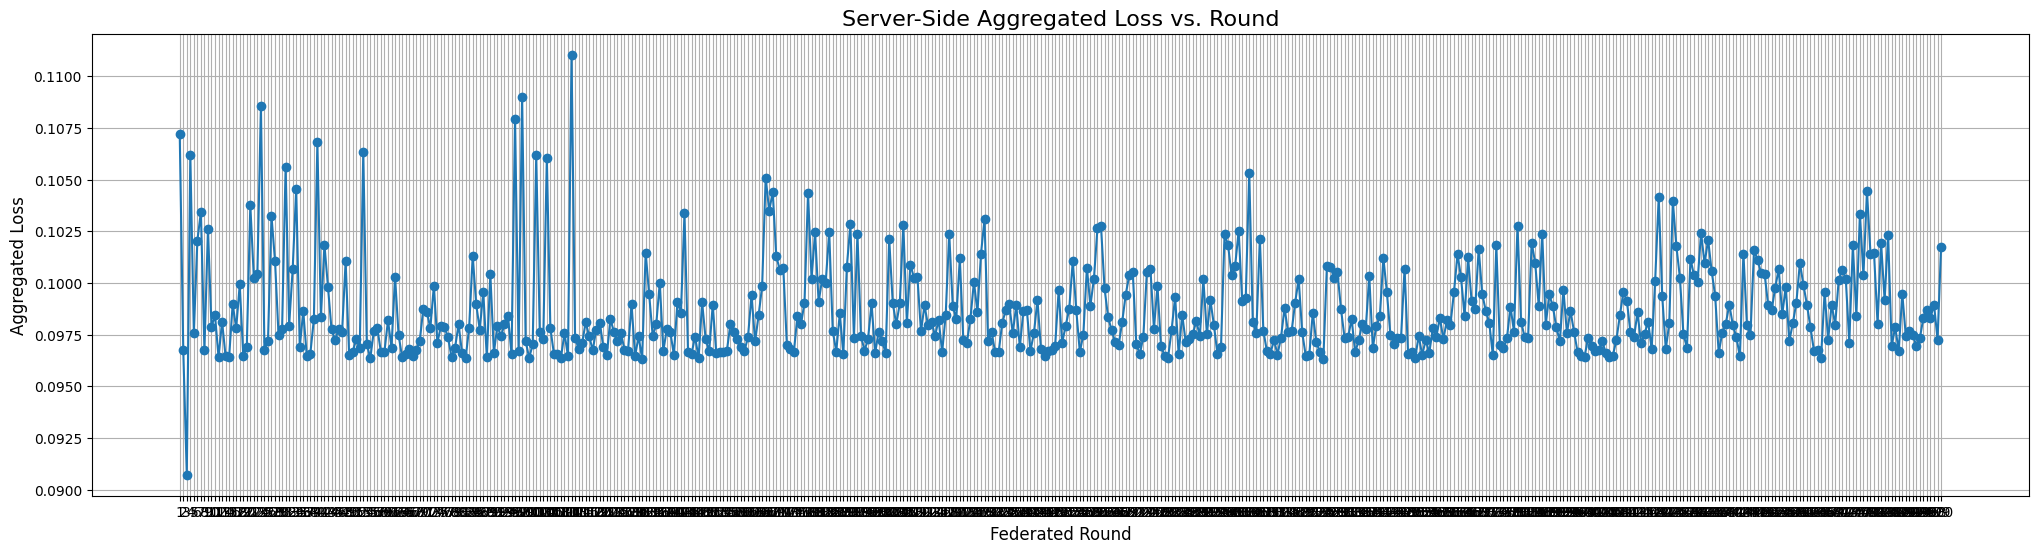

In [31]:
import matplotlib.pyplot as plt

rounds = [rnd for rnd, _ in Output_History.losses_distributed]
losses = [loss for _, loss in Output_History.losses_distributed]

plt.figure(figsize=(25, 6))
plt.plot(rounds, losses, marker='o', linestyle='-')
plt.title("Server-Side Aggregated Loss vs. Round", fontsize=16)
plt.xlabel("Federated Round", fontsize=12)
plt.ylabel("Aggregated Loss", fontsize=12)
plt.grid(True)
plt.xticks(rounds)

plt.savefig("../results/server_loss_plot.png")

plt.show()

In [32]:
# print(Output_History)

In [33]:
# print(Output_History.metrics_centralized.items())
# Access the list of (round, value) tuples for the metric
# r2_history = Output_History.metrics_centralized['r2_feature_0']

# Get the number of entries (which corresponds to the number of rounds)
# num_entries = len(r2_history)

# print(f"Number of logged entries for 'r2_feature_0': {num_entries}")

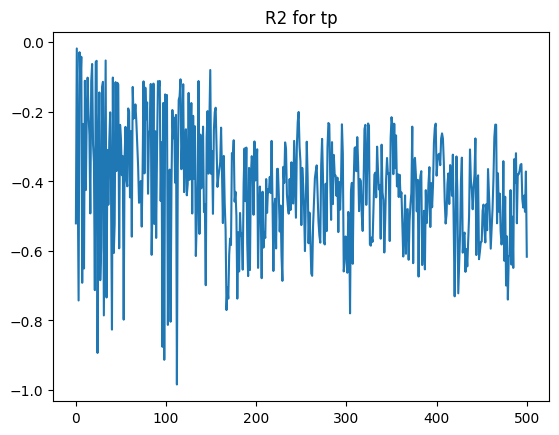

The maximum R² score for throughput is: -0.0178


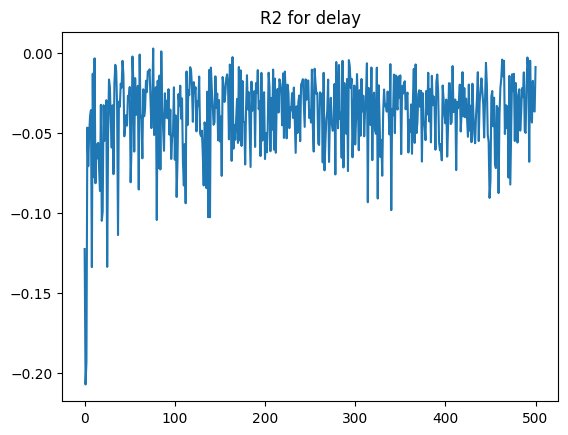

The maximum R² score for delay is: 0.0027


In [34]:
r2_history1 = Output_History.metrics_centralized['r2_feature_0']
r2_history2 = Output_History.metrics_centralized['r2_feature_1']
# print(r2_history1)

scores = [score for round_num, score in r2_history1]
plt.plot(scores)
plt.title("R2 for tp")
plt.show()
max_score = max(scores)

print(f"The maximum R² score for throughput is: {max_score:.4f}")

# del scores

scores = [score for round_num, score in r2_history2]
plt.plot(scores)
plt.title("R2 for delay")
plt.show()
max_score = max(scores)

print(f"The maximum R² score for delay is: {max_score:.4f}")

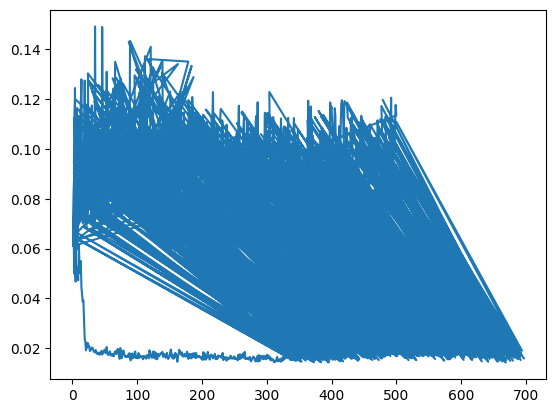

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
client_log = pd.read_csv('../results/client_0_log.csv')
# print(client_log.shape)
# client_log = client_log[915:]
# print(client_log.shape)
# client_log.head()
plt.plot(client_log['round'], client_log['val_loss'], label='val_loss')
plt.show()

In [ ]:

client_log.head()

,round,train_loss,val_loss,r2_throughput,r2_delay
0,1,-1.0,0.066806,-0.061664,-0.390146
1,2,-1.0,0.069644,-0.062053,-0.201519
2,3,-1.0,0.075508,-0.139910,-0.057426
3,4,-1.0,0.088254,-0.301548,-0.038071
4,5,-1.0,0.078602,-0.177240,-0.038765


: 